# Demo: the admission problem

In this notebook we will run one episode of the admission demo, a simplified admission problem and a one-line policy against the baselines.

![Decision seams: admission sits in the search](../_static/figures/seams.png)

In [7]:
import logging
from pathlib import Path

import pandas as pd

from rl.env import UmosimEnv
from rl.problems import AdmissionProblem
from rl.problems.admission import DEFER, FEATURES, OFFER

logging.disable(logging.INFO)

PROJECT = Path("../../data/projects/ridehailing_admission_demo")
if not PROJECT.is_dir():
    msg = f"{PROJECT.resolve()} is missing. Run `uv run umosim demo` from the repository root."
    raise FileNotFoundError(msg)

## The environment

![The rl package](../_static/figures/rl-package.png)

`reset` builds the day and runs it to the first search that finds vehicles.
`horizon_min=180` ends the episode at 3:00.

In [8]:
env = UmosimEnv(PROJECT, AdmissionProblem(), horizon_min=180)
observation, info = env.reset(seed=1)
info

{'revenue': 0.0,
 'cost': 1.7518016554468465,
 'profit': -1.7518016554468465,
 'fulfilled': 0,
 'offered': 0,
 'deferred': 0,
 'period_start_min': 0,
 'period_end_min': 1.7397202647196268}

## The observation

14 entries: six fleet shares, five for the pending search, the yield, the time of day.

In [9]:
pd.Series(observation, index=FEATURES).round(3)

standby                 1.000
transporting            0.000
relocating              0.000
waiting_for_charging    0.000
charging                0.000
offline                 0.000
candidates              0.320
pickup                  0.265
trip                    0.455
fare                    0.738
searched                0.000
yield                   0.000
clock_sin               0.008
clock_cos               1.000
dtype: float32

## One step
Two actions. `step` hands the reply to the waiting search and runs on to the next decision point.
The reward is the profit of the settled period.

In [10]:
DEFER, OFFER

(0, 1)

In [11]:
observation, reward, terminated, truncated, info = env.step(OFFER)
reward, info

(-0.8009796545465897,
 {'revenue': 0.0,
  'cost': 0.8009796545465897,
  'profit': -0.8009796545465897,
  'fulfilled': 0,
  'offered': 1,
  'deferred': 0,
  'period_start_min': 1.7397202647196268,
  'period_end_min': 2.535175921648654})

## One episode

Offer on every search:

In [12]:
observation, info = env.reset(seed=1)
steps, total_reward = 0, 0.0
while True:
    observation, reward, terminated, truncated, info = env.step(OFFER)
    steps += 1
    total_reward += reward
    if terminated or truncated:
        break
steps, round(total_reward, 1), terminated, truncated

(263, 458.3, False, True)

## A simplified admission problem

Three features instead of 14: pickup leg (km), trip (km), share of the fleet in standby.
Two spaces, `build_observation` and `apply_action`. The reward stays the profit of `OperatorProblem`.

In [13]:
import numpy as np
from gymnasium.spaces import Box, Discrete

from rl.channel import DecisionRequest
from rl.operator_problem import OperatorProblem
from rl.problem import Period
from rl.problems.features import state_shares
from simulation.simulation import Simulation

PICKUP, TRIP, STANDBY = range(3)


class SmallAdmissionProblem(OperatorProblem):
    """An OperatorProblem that offers or defers each search from three features."""

    @property
    def observation_space(self) -> Box:
        """Pickup leg and trip (km), share of the fleet in standby (0 to 1)."""
        return Box(low=0.0, high=np.inf, shape=(3,), dtype=np.float32)

    @property
    def action_space(self) -> Discrete:
        """Action 0 defers, action 1 offers."""
        return Discrete(2)

    def build_observation(
        self, simulation: Simulation, period: Period, request: DecisionRequest | None
    ) -> np.ndarray:
        """Return the three features at the decision point the simulation is frozen at."""
        standby = state_shares(self.operator.fleet.vehicles)["standby"]
        if request is None:  # the horizon, no search is pending
            return np.array([0.0, 0.0, standby], dtype=np.float32)
        search = request.payload
        pickup_m = min(
            alternative.route_to_pickup.distance for alternative in search.alternatives
        )
        trip_m = search.alternatives[0].distance  # one trip, the same for every vehicle
        return np.array([pickup_m / 1000, trip_m / 1000, standby], dtype=np.float32)

    def apply_action(
        self, simulation: Simulation, request: DecisionRequest, action: int
    ) -> bool:
        """Return the reply to the waiting search: True offers, False defers."""
        return bool(action)

Same seed, same world: the first decision point again, through three features.

In [14]:
small_env = UmosimEnv(PROJECT, SmallAdmissionProblem(), horizon_min=180)
observation, info = small_env.reset(seed=1)
observation

array([2.647786, 8.358045, 1.      ], dtype=float32)

## Baseline: the numbers to beat

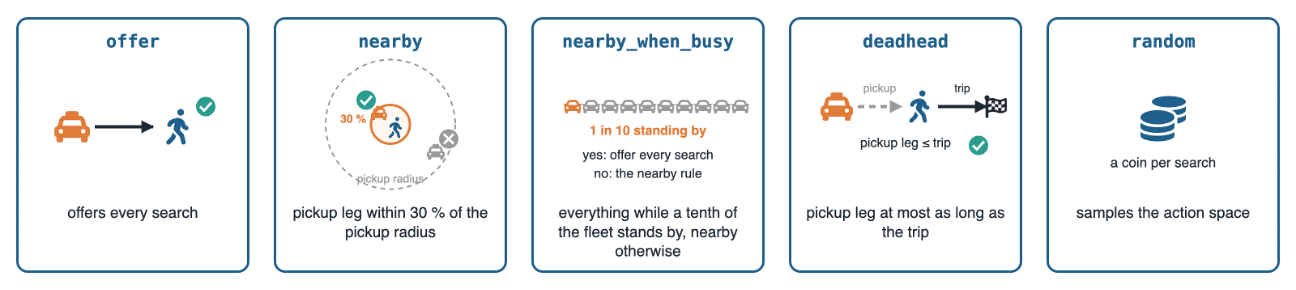

There are five admission baselines. They’re fixed policies, defined as ADMISSION_BASELINES in scripts/rl_baselines.py:106.

1. offer: offers every search.
2. nearby: offers only when the nearest pickup leg is at most 30% of the pickup radius (NEARBY_SHARE = 0.3).
3. nearby_when_busy: offers everything while at least 10% of the fleet stands by (IDLE_SHARE = 0.1). Otherwise it falls back to nearby.
4. deadhead: offers when the pickup leg is at most as long as the trip itself (DEADHEAD_MULTIPLE = 1.0).
5. random: samples offer or defer at random, seeded per episode.

In [15]:
from scripts.rl_baselines import ADMISSION_BASELINES, Outcome, sweep

HORIZON_MIN = 720
SEEDS = [1, 2, 3]


def summary(results: dict[str, list[Outcome]]) -> pd.DataFrame:
    """Return the mean outcome of each policy over the seeds, with the stdev of its profit."""
    rows = {}
    for name, outcomes in results.items():
        episodes = pd.DataFrame(outcomes)
        rows[name] = episodes.mean()
        rows[name]["profit_stdev"] = episodes["profit"].std()
    table = pd.DataFrame(rows).T
    return table[["profit", "profit_stdev", "fulfilled", "lost", "wait_min"]].round(1)

In [17]:
baselines = sweep(PROJECT, AdmissionProblem(), ADMISSION_BASELINES, SEEDS, HORIZON_MIN)
summary(baselines)

,profit,profit_stdev,fulfilled,lost,wait_min
offer,6037.3,219.0,505.3,755.0,35.2
nearby,6304.3,180.7,526.7,740.0,26.1
nearby_when_busy,6416.1,59.3,528.0,737.0,30.3
deadhead,6343.2,50.3,443.7,821.0,31.4
random,6114.7,171.6,503.7,761.3,31.2


## Our own policy

On the three features: offer everything while a tenth of the fleet stands by, else pickups of 2.5 km at most.
Feel free to experiment :)

In [ ]:
def busy_aware(observation: np.ndarray) -> bool:
    """Offer every search while a tenth of the fleet stands by, else pickups of 2.5 km at most."""
    return observation[STANDBY] >= 0.1 or observation[PICKUP] <= 2.5


# reminder: our Problem defines PICKUP, TRIP, STANDBY

mine = sweep(
    PROJECT, SmallAdmissionProblem(), {"busy_aware": busy_aware}, SEEDS, HORIZON_MIN
)
summary({**baselines, **mine})

,profit,profit_stdev,fulfilled,lost,wait_min
offer,6037.3,219.0,505.3,755.0,35.2
nearby,6304.3,180.7,526.7,740.0,26.1
nearby_when_busy,6416.1,59.3,528.0,737.0,30.3
deadhead,6343.2,50.3,443.7,821.0,31.4
random,6114.7,171.6,503.7,761.3,31.2
busy_aware,6470.1,145.6,544.0,727.0,28.2


## A learned policy

Stable-Baselines3 trains on any Gymnasium environment, `UmosimEnv` included.
A DQN with the defaults, on the three features, 20,000 steps to noon. About a minute.

In [ ]:
from stable_baselines3 import DQN

train_env = UmosimEnv(PROJECT, SmallAdmissionProblem(), horizon_min=HORIZON_MIN)
model = DQN("MlpPolicy", train_env, seed=0)
model.learn(total_timesteps=20_000)
train_env.close()


def dqn(observation: np.ndarray) -> int:
    """Return the greedy action of the model."""
    return int(model.predict(observation, deterministic=True)[0])


learned = sweep(PROJECT, SmallAdmissionProblem(), {"dqn": dqn}, SEEDS, HORIZON_MIN)
summary({**baselines, **mine, **learned})

,profit,profit_stdev,fulfilled,lost,wait_min
offer,6037.3,219.0,505.3,755.0,35.2
nearby,6304.3,180.7,526.7,740.0,26.1
nearby_when_busy,6416.1,59.3,528.0,737.0,30.3
deadhead,6343.2,50.3,443.7,821.0,31.4
random,6114.7,171.6,503.7,761.3,31.2
busy_aware,6470.1,145.6,544.0,727.0,28.2
dqn,4599.3,73.9,585.7,686.7,25.6


In [ ]:
env.close()
small_env.close()